In [5]:
!pip install git+https://github.com/facebookresearch/detectron2.git --no-build-isolation

  Cloning https://github.com/facebookresearch/detectron2.git to /tmp/pip-req-build-n13zx3bg
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/detectron2.git /tmp/pip-req-build-n13zx3bg
  Resolved https://github.com/facebookresearch/detectron2.git to commit 247691a1c292654867deb35cabb27f18d75a1363
  Preparing metadata (pyproject.toml) ... done


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
model_final_f10217.pkl: 178MB [00:02, 87.5MB/s]                           
/usr/local/lib/python3.13/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorc

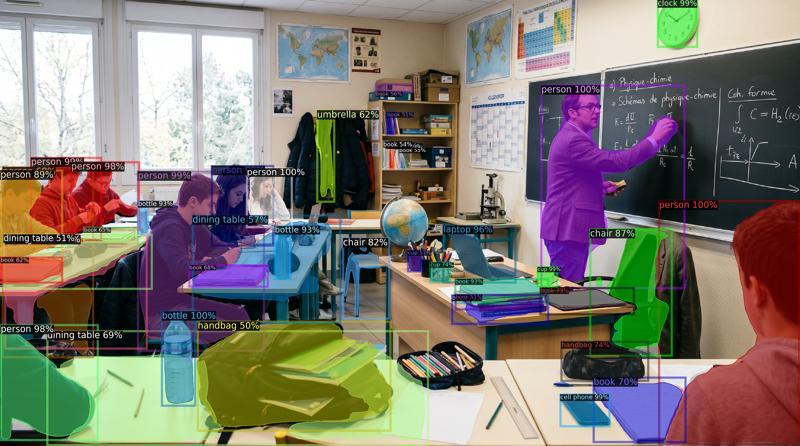

In [ ]:
import cv2
import torch
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog
from google.colab.patches import cv2_imshow # Import spécifique pour l'affichage sur Colab

# Configuration du modèle pré-entraîné
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"))
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5  
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")
cfg.MODEL.DEVICE = "cpu" # Forcer l'utilisation du CPU sur Colab

predictor = DefaultPredictor(cfg)

# Charger une image
img = cv2.imread("image_objects.jpg")

# Prédiction
outputs = predictor(img)

# Visualisation
v = Visualizer(img[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=1.2)
out = v.draw_instance_predictions(outputs["instances"].to("cpu"))

# Affichage du résultat avec la fonction de Colab
cv2_imshow(out.get_image()[:, :, ::-1])

### Réponses - Exercice 3

**1. Quels objets ont été détectés ?**
En observant le résultat de l'inférence sur l'image de la salle de classe, le modèle Mask R-CNN a détecté avec succès une grande variété d'objets avec d'excellents scores de confiance :
*   **Personnes** : Le professeur (person 100%) et les élèves (person 89% à 100%).
*   **Mobilier** : Les tables (dining table 51% à 69%) et les chaises (chair 82% à 87%).
*   **Fournitures et objets scolaires** : Des livres/cahiers (book 54% à 70%), des sacs à dos (handbag 50% à 74%), des bouteilles d'eau (bottle 93% à 100%), un ordinateur portable (laptop 96%), un téléphone portable (cell phone 99%) et même l'horloge au mur (clock 99%).
*   **Vêtements** : Le manteau accroché au fond a été identifié (umbrella 62% - *il s'agit ici d'une légère erreur de classification du modèle sur la forme du vêtement*).

**2. Modifiez le seuil SCORE_THRESH_TEST et observez l'effet sur la détection.**
- Si l'on augmente le seuil (ex: `0.9`), le modèle devient plus strict. Il n'affichera que les objets dont il est absolument certain (comme le professeur à 100% ou le téléphone à 99%). Cela éliminera les faux positifs potentiels (comme le manteau confondu avec un parapluie à 62%), mais on perdra la détection de certains objets réels qui ont un score plus faible (comme certains sacs ou tables).
- Si l'on diminue le seuil (ex: `0.2`), le modèle est plus permissif. Il détectera plus de choses en arrière-plan (peut-être les stylos individuels ou les affiches), mais le nombre de fausses détections augmentera drastiquement, rendant l'image illisible sous une accumulation de masques erronés.

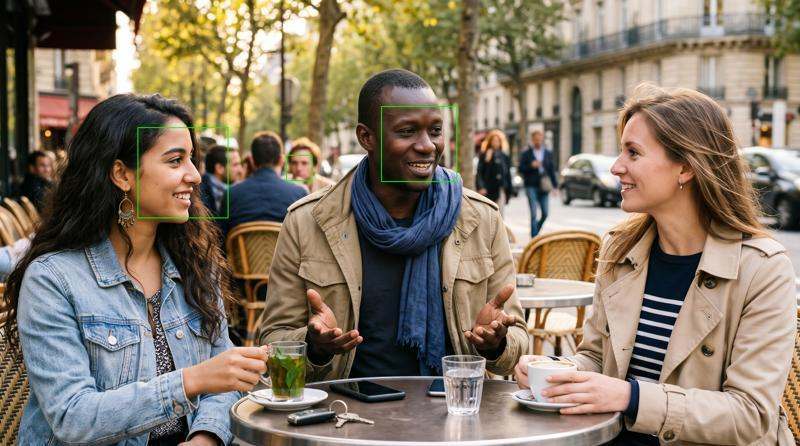

In [9]:
import dlib
import cv2
from google.colab.patches import cv2_imshow # Import indispensable sur Colab

detector = dlib.get_frontal_face_detector()

# Utilisation du chemin absolu vers la racine de Colab
img = cv2.imread("/people.jpg")

# Vérification de sécurité
if img is None:
    print("Erreur : Impossible de charger l'image. Vérifiez le nom du fichier.")
else:
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = detector(gray)

    for face in faces:
        x, y, w, h = face.left(), face.top(), face.width(), face.height()
        cv2.rectangle(img, (x, y), (x+w, y+h), (0, 255, 0), 2)

    # Affichage de l'image avec les visages détectés
    cv2_imshow(img)

In [4]:
!pip install face_recognition

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.1/100.1 MB 51.0 MB/s  0:00:02
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for face-recognition-models: filename=face_recognition_models-0.3.0-py2.py3-none-any.whl size=100566240 sha256=86830ef4b9c88042b630313dfc50dd346991d17c25ba8bd6412b60e709422ab6
  Stored in directory: /root/.cache/pip/wheels/39/20/47/6b647a3457f0e36c161b2516a5bd7f29f6bbd5e3a67c46a710
Successfully built face-recognition-models
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [face_recognition]


In [ ]:
import face_recognition
import os


os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

# Charger les images
image_ref = face_recognition.load_image_file("ref.jpg")
encodage_ref = face_recognition.face_encodings(image_ref)[0]

image_test = face_recognition.load_image_file("test.jpg")
encodage_test = face_recognition.face_encodings(image_test)[0]

# Comparer
result = face_recognition.compare_faces([encodage_ref], encodage_test)
print("Même personne ?", result[0])

Même personne ? True




### Réponses - Exercice 5
**1. Que se passe-t-il si l'image test contient plusieurs visages ?**
La fonction `face_encodings(image_test)` renvoie une liste contenant les encodages de *tous* les visages présents. En appelant `[0]` à la fin, on ne récupère que l'encodage du tout premier visage trouvé dans l'image. Pour vérifier tous les visages, il faudrait faire une boucle `for` sur la liste complète retournée par `face_encodings` et les comparer un à un à `encodage_ref`.

**2. Quelle précision attendez-vous de ce système dans des conditions réelles (lumière, angles différents) ?**
Dans des conditions optimales (visage de face, bon éclairage), la bibliothèque `face_recognition` (basée sur le modèle ResNet de Dlib) offre une excellente précision. En revanche, dans des conditions réelles non contrôlées, la précision chute :
- **Lumière** : Les fortes zones d'ombres ou la sous-exposition faussent le calcul des caractéristiques du visage.
- **Angles** : Le système de base (frontal) tolère mal les rotations extrêmes ou les visages de profil strict.
- **Occlusions** : La présence de lunettes de soleil, masques ou écharpes diminue le nombre de *landmarks* détectables, rendant l'identification incertaine.